# Phase 1: IoMT Dataset Unification Pipeline

This notebook executes the Phase 1 integration pipeline described in **Chapter 3** of the thesis.

**Objective:** Unify the two IoMT-specific datasets (CICIoMT2024 and IoMT-TrafficData),
both processed through MIOTTA-NPT with identical configuration (combined mode, window size 100),
into a single ML-ready dataset with harmonized labels, quality assurance, and provenance tracking.

**Pipeline Stages:**
1. Data Loading & Source Attribution
2. Cross-Dataset Feature Verification
3. Label Harmonization (3-level scheme)
4. Dataset Concatenation & Source Attribution
5. Data Quality Assurance
6. Stratified Splitting (70/15/15)
7. Feature Scaling (z-score standardization)
8. Export & Final Verification

In [1]:
import sys
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from pipeline.loader import load_ciciomt2024, load_iomt_trafficdata, get_feature_columns
from pipeline.harmonizer import harmonize_ciciomt2024, harmonize_iomt_trafficdata, print_label_summary
from pipeline.quality import run_full_qa
from pipeline.scaling import stratified_split, apply_scaling, print_split_distribution
from pipeline.exporter import save_splits
from pipeline.config import CICIOMT_CATEGORY_MAP, IOMT_CATEGORY_MAP, IOMT_FINE_MAP

pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 30)
sns.set_theme(style='whitegrid')

print('Pipeline modules loaded successfully.')

Pipeline modules loaded successfully.


---
## Stage 1: Data Loading & Source Attribution

Load all MIOTTA-processed CSV files from both datasets.
Each record is tagged with:
- `source_dataset`: identifies the originating dataset
- `source_file`: the specific MIOTTA output CSV file
- `attack_type`: the attack label inferred from the filename
- `attack_group`: normalized attack group (numeric suffixes stripped)

In [2]:
print('='*70)
print('STAGE 1: Data Loading & Source Attribution')
print('='*70)

cic = load_ciciomt2024()
print(f'\nCICIoMT2024 shape: {cic.shape}')
print(f'Columns: {list(cic.columns[:5])} ... {list(cic.columns[-5:])}')

STAGE 1: Data Loading & Source Attribution
Loading CICIoMT2024-MIOTTA (train)...
  ARP_Spoofing_train.csv                                       → label='ARP_Spoofing             ' rows=   1,607
  Benign_train.csv                                             → label='Benign                   ' rows=  19,357


  MQTT-DDoS-Connect_Flood_train.csv                            → label='MQTT-DDoS-Connect_Flood  ' rows= 172,960
  MQTT-DDoS-Publish_Flood_train.csv                            → label='MQTT-DDoS-Publish_Flood  ' rows=  27,543
  MQTT-DoS-Connect_Flood_train.csv                             → label='MQTT-DoS-Connect_Flood   ' rows=  12,770


  MQTT-DoS-Publish_Flood_train.csv                             → label='MQTT-DoS-Publish_Flood   ' rows=  44,316
  MQTT-Malformed_Data_train.csv                                → label='MQTT-Malformed_Data      ' rows=     514
  Recon-OS_Scan_train.csv                                      → label='Recon-OS_Scan            ' rows=   1,684
  Recon-Ping_Sweep_train.csv                                   → label='Recon-Ping_Sweep         ' rows=      75
  Recon-Port_Scan_train.csv                                    → label='Recon-Port_Scan          ' rows=   8,400
  Recon-VulScan_train.csv                                      → label='Recon-VulScan            ' rows=     218


  TCP_IP-DDoS-ICMP1_train.csv                                  → label='TCP_IP-DDoS-ICMP1        ' rows= 194,862


  TCP_IP-DDoS-ICMP2_train.csv                                  → label='TCP_IP-DDoS-ICMP2        ' rows= 194,755


  TCP_IP-DDoS-ICMP3_train.csv                                  → label='TCP_IP-DDoS-ICMP3        ' rows= 189,638


... (46 outputs left out)

  estadisticas_combinadas_TCP_IP-DoS-SYN_test.csv              → label='TCP_IP-DoS-SYN           ' rows=  98,547


  estadisticas_combinadas_TCP_IP-DoS-TCP_test.csv              → label='TCP_IP-DoS-TCP           ' rows=  82,064


  estadisticas_combinadas_TCP_IP-DoS-UDP_test.csv              → label='TCP_IP-DoS-UDP           ' rows= 137,496



CICIoMT2024 total: 8,423,955 rows × 77 columns

CICIoMT2024 shape: (8423955, 77)
Columns: ['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'fin_flag_number'] ... ['Flow_IAT', 'attack_type', 'source_file', 'source_dataset', 'attack_group']


In [3]:
iomt = load_iomt_trafficdata()
print(f'\nIoMT-TrafficData shape: {iomt.shape}')
print(f'Columns: {list(iomt.columns[:5])} ... {list(iomt.columns[-5:])}')

Loading IoMT-TrafficData-MIOTTA...
  estadisticas_combinadas_ARP Spoofing 01.csv                  → label='ARP Spoofing 01          ' rows=   3,783
  estadisticas_combinadas_ARP Spoofing 02.csv                  → label='ARP Spoofing 02          ' rows=   3,780
  estadisticas_combinadas_Apache Killer.csv                    → label='Apache Killer            ' rows=  10,772
  estadisticas_combinadas_CAM Table Overflow.csv               → label='CAM Table Overflow       ' rows=  23,984


  estadisticas_combinadas_IP-Based Normal Capture.csv          → label='IP-Based Normal Capture  ' rows=  30,323


  estadisticas_combinadas_MQTT Malaria.csv                     → label='MQTT Malaria             ' rows=  65,734
  estadisticas_combinadas_Net Scan.csv                         → label='Net Scan                 ' rows=  32,879
  estadisticas_combinadas_RUDY.csv                             → label='RUDY                     ' rows=   7,809
  estadisticas_combinadas_Slow Loris.csv                       → label='Slow Loris               ' rows=   3,778


  estadisticas_combinadas_Slow Read.csv                        → label='Slow Read                ' rows=   1,399

IoMT-TrafficData total: 184,241 rows × 77 columns

IoMT-TrafficData shape: (184241, 77)
Columns: ['Window', 'Header_Length', 'Protocol_Type', 'TTL', 'fin_flag_number'] ... ['Flow_IAT', 'attack_type', 'source_file', 'source_dataset', 'attack_group']


In [4]:
print(f'\n--- Source Attribution Verification ---')
print(f'CICIoMT2024 unique attack types:   {cic["attack_group"].nunique()}')
print(f'IoMT-TrafficData unique attack types: {iomt["attack_type"].nunique()}')
print(f'\nCICIoMT2024 attack groups:')
for grp, cnt in cic['attack_group'].value_counts().items():
    print(f'  {grp:35s} {cnt:>10,}')
print(f'\nIoMT-TrafficData attack types:')
for typ, cnt in iomt['attack_type'].value_counts().items():
    print(f'  {typ:35s} {cnt:>10,}')


--- Source Attribution Verification ---


CICIoMT2024 unique attack types:   19
IoMT-TrafficData unique attack types: 10

CICIoMT2024 attack groups:


  TCP_IP-DDoS-UDP                      1,997,256
  TCP_IP-DDoS-ICMP                     1,886,447
  TCP_IP-DDoS-TCP                        986,680
  TCP_IP-DDoS-SYN                        973,999
  TCP_IP-DoS-UDP                         704,215
  TCP_IP-DoS-SYN                         540,281
  TCP_IP-DoS-ICMP                        514,504
  TCP_IP-DoS-TCP                         462,307
  MQTT-DDoS-Connect_Flood                214,860
  MQTT-DoS-Publish_Flood                  52,809
  MQTT-DDoS-Publish_Flood                 35,946
  Benign                                  23,133
  MQTT-DoS-Connect_Flood                  15,900
  Recon-Port_Scan                         10,663
  Recon-OS_Scan                            2,068
  ARP_Spoofing                             1,782
  MQTT-Malformed_Data                        689
  Recon-VulScan                              322
  Recon-Ping_Sweep                            94

IoMT-TrafficData attack types:
  MQTT Malaria                       

---
## Stage 2: Cross-Dataset Feature Verification

Confirm that both MIOTTA-processed datasets share identical column names, data types, and column order.
This is a prerequisite for concatenation.

In [5]:
print('='*70)
print('STAGE 2: Cross-Dataset Feature Verification')
print('='*70)

cic_features = get_feature_columns(cic)
iomt_features = get_feature_columns(iomt)

print(f'CICIoMT2024 features:       {len(cic_features)}')
print(f'IoMT-TrafficData features:  {len(iomt_features)}')

if set(cic_features) == set(iomt_features):
    print('\n✓ Feature sets are IDENTICAL')
else:
    only_cic = set(cic_features) - set(iomt_features)
    only_iomt = set(iomt_features) - set(cic_features)
    print(f'\n✗ MISMATCH!')
    if only_cic: print(f'  Only in CICIoMT2024: {only_cic}')
    if only_iomt: print(f'  Only in IoMT-TrafficData: {only_iomt}')

if list(cic_features) == list(iomt_features):
    print('✓ Column ORDER is identical')
else:
    print('✗ Column order differs')

STAGE 2: Cross-Dataset Feature Verification
CICIoMT2024 features:       73
IoMT-TrafficData features:  73

✓ Feature sets are IDENTICAL
✓ Column ORDER is identical


In [6]:
print('Data type comparison (all 73 features):\n')
mismatches = 0
for feat in cic_features:
    cic_dtype = cic[feat].dtype
    iomt_dtype = iomt[feat].dtype
    match = '✓' if cic_dtype == iomt_dtype else '✗'
    if cic_dtype != iomt_dtype:
        print(f'  {match} {feat:35s}  CIC: {str(cic_dtype):10s}  IoMT: {str(iomt_dtype):10s}')
        mismatches += 1
if mismatches == 0:
    print(f'  ✓ All {len(cic_features)} features have matching data types')
else:
    print(f'\n  {mismatches} type mismatches found')

Data type comparison (all 73 features):

  ✓ All 73 features have matching data types


---
## Stage 3: Label Harmonization (3-Level Scheme)

Apply the three-level labeling scheme from Section 3.5:
- **Level 1 — Binary:** Benign / Attack
- **Level 2 — Category:** 6 categories for Phase 1 (Benign, DDoS, DoS, Reconnaissance, Spoofing, Injection)
- **Level 3 — Fine-grained:** Original attack type labels, normalized

In [7]:
print('='*70)
print('STAGE 3: Label Harmonization')
print('='*70)

print('\n--- CICIoMT2024 Category Mapping ---')
for orig, cat in sorted(CICIOMT_CATEGORY_MAP.items()):
    print(f'  {orig:35s} → {cat}')

STAGE 3: Label Harmonization

--- CICIoMT2024 Category Mapping ---
  ARP_Spoofing                        → Spoofing
  Benign                              → Benign
  MQTT-DDoS-Connect_Flood             → DDoS
  MQTT-DDoS-Publish_Flood             → DDoS
  MQTT-DoS-Connect_Flood              → DoS
  MQTT-DoS-Publish_Flood              → DoS
  MQTT-Malformed_Data                 → Injection
  Recon-OS_Scan                       → Reconnaissance
  Recon-Ping_Sweep                    → Reconnaissance
  Recon-Port_Scan                     → Reconnaissance
  Recon-VulScan                       → Reconnaissance
  TCP_IP-DDoS-ICMP                    → DDoS
  TCP_IP-DDoS-SYN                     → DDoS
  TCP_IP-DDoS-TCP                     → DDoS
  TCP_IP-DDoS-UDP                     → DDoS
  TCP_IP-DoS-ICMP                     → DoS
  TCP_IP-DoS-SYN                      → DoS
  TCP_IP-DoS-TCP                      → DoS
  TCP_IP-DoS-UDP                      → DoS


In [8]:
print('--- IoMT-TrafficData Category Mapping ---')
for orig, cat in sorted(IOMT_CATEGORY_MAP.items()):
    print(f'  {orig:35s} → {cat}')
print('\n--- IoMT-TrafficData Fine-Grained Mapping ---')
for orig, fine in sorted(IOMT_FINE_MAP.items()):
    print(f'  {orig:35s} → {fine}')

--- IoMT-TrafficData Category Mapping ---
  ARP Spoofing 01                     → Spoofing
  ARP Spoofing 02                     → Spoofing
  Apache Killer                       → DoS
  CAM Table Overflow                  → DoS
  IP-Based Normal Capture             → Benign
  MQTT Malaria                        → DoS
  Net Scan                            → Reconnaissance
  RUDY                                → DoS
  Slow Loris                          → DoS
  Slow Read                           → DoS

--- IoMT-TrafficData Fine-Grained Mapping ---
  ARP Spoofing 01                     → ARP_Spoofing
  ARP Spoofing 02                     → ARP_Spoofing
  Apache Killer                       → Apache_Killer
  CAM Table Overflow                  → CAM_Table_Overflow
  IP-Based Normal Capture             → Benign
  MQTT Malaria                        → MQTT_Malaria
  Net Scan                            → Net_Scan
  RUDY                                → RUDY
  Slow Loris                      

In [9]:
cic = harmonize_ciciomt2024(cic)
print_label_summary(cic, 'CICIoMT2024')


Label Summary: CICIoMT2024

--- Level 1: Binary ---
  Attack           8,400,822  ( 99.73%)
  Benign              23,133  (  0.27%)

--- Level 2: Category ---


  DDoS                  6,095,188  ( 72.36%)
  DoS                   2,290,016  ( 27.18%)
  Benign                   23,133  (  0.27%)
  Reconnaissance           13,147  (  0.16%)
  Spoofing                  1,782  (  0.02%)
  Injection                   689  (  0.01%)

--- Level 3: Fine-grained ---


  TCP_IP-DDoS-UDP                 1,997,256  ( 23.71%)
  TCP_IP-DDoS-ICMP                1,886,447  ( 22.39%)
  TCP_IP-DDoS-TCP                   986,680  ( 11.71%)
  TCP_IP-DDoS-SYN                   973,999  ( 11.56%)
  TCP_IP-DoS-UDP                    704,215  (  8.36%)
  TCP_IP-DoS-SYN                    540,281  (  6.41%)
  TCP_IP-DoS-ICMP                   514,504  (  6.11%)
  TCP_IP-DoS-TCP                    462,307  (  5.49%)
  MQTT-DDoS-Connect_Flood           214,860  (  2.55%)
  MQTT-DoS-Publish_Flood             52,809  (  0.63%)
  MQTT-DDoS-Publish_Flood            35,946  (  0.43%)
  Benign                             23,133  (  0.27%)
  MQTT-DoS-Connect_Flood             15,900  (  0.19%)
  Recon-Port_Scan                    10,663  (  0.13%)
  Recon-OS_Scan                       2,068  (  0.02%)
  ARP_Spoofing                        1,782  (  0.02%)
  MQTT-Malformed_Data                   689  (  0.01%)
  Recon-VulScan                         322  (  0.00%)
  Recon-Pi

In [10]:
iomt = harmonize_iomt_trafficdata(iomt)
print_label_summary(iomt, 'IoMT-TrafficData')


Label Summary: IoMT-TrafficData

--- Level 1: Binary ---
  Attack             153,918  ( 83.54%)
  Benign              30,323  ( 16.46%)

--- Level 2: Category ---
  DoS                     113,476  ( 61.59%)
  Reconnaissance           32,879  ( 17.85%)
  Benign                   30,323  ( 16.46%)
  Spoofing                  7,563  (  4.10%)

--- Level 3: Fine-grained ---
  MQTT_Malaria                       65,734  ( 35.68%)
  Net_Scan                           32,879  ( 17.85%)
  Benign                             30,323  ( 16.46%)
  CAM_Table_Overflow                 23,984  ( 13.02%)
  Apache_Killer                      10,772  (  5.85%)
  RUDY                                7,809  (  4.24%)
  ARP_Spoofing                        7,563  (  4.10%)
  SlowLoris                           3,778  (  2.05%)
  SlowRead                            1,399  (  0.76%)


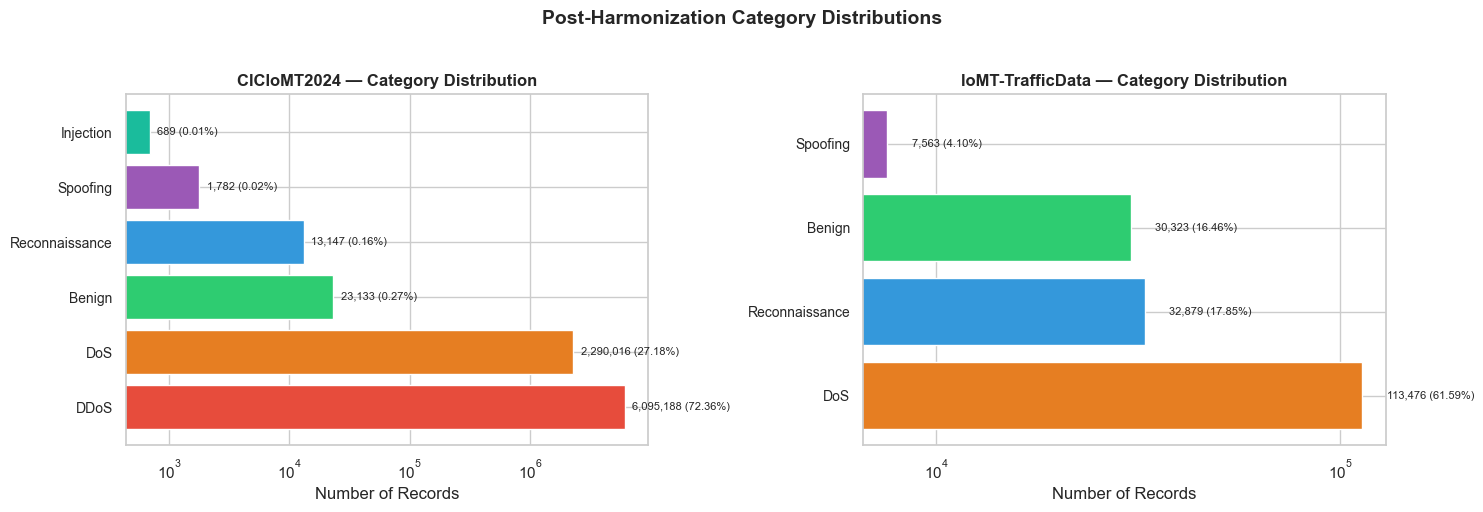

In [11]:
# Visualize category distributions side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cat_colors = {
    'DDoS': '#e74c3c', 'DoS': '#e67e22', 'Benign': '#2ecc71',
    'Reconnaissance': '#3498db', 'Spoofing': '#9b59b6', 'Injection': '#1abc9c',
}

for ax, df, title in [(axes[0], cic, 'CICIoMT2024'), (axes[1], iomt, 'IoMT-TrafficData')]:
    cats = df['label_category'].value_counts()
    colors = [cat_colors.get(c, '#95a5a6') for c in cats.index]
    bars = ax.barh(range(len(cats)), cats.values, color=colors, edgecolor='white')
    ax.set_yticks(range(len(cats)))
    ax.set_yticklabels(cats.index, fontsize=10)
    ax.set_xlabel('Number of Records')
    ax.set_xscale('log')
    ax.set_title(f'{title} — Category Distribution', fontweight='bold')
    for bar, val in zip(bars, cats.values):
        pct = 100 * val / len(df)
        ax.text(val * 1.15, bar.get_y() + bar.get_height()/2,
                f'{val:,} ({pct:.2f}%)', va='center', fontsize=8)

plt.suptitle('Post-Harmonization Category Distributions', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Stage 4: Dataset Concatenation & Source Attribution

Merge both harmonized datasets into a single DataFrame. The `source_dataset` column preserves provenance.

In [12]:
print('='*70)
print('STAGE 4: Dataset Concatenation')
print('='*70)

unified = pd.concat([cic, iomt], ignore_index=True)
print(f'Unified dataset: {len(unified):,} rows × {unified.shape[1]} columns')
print(f'\nSource distribution:')
for src, count in unified['source_dataset'].value_counts().items():
    pct = 100 * count / len(unified)
    print(f'  {src:20s} {count:>10,}  ({pct:5.2f}%)')

STAGE 4: Dataset Concatenation


Unified dataset: 8,608,196 rows × 80 columns

Source distribution:
  CICIoMT2024           8,423,955  (97.86%)
  IoMT-TrafficData        184,241  ( 2.14%)


In [13]:
print_label_summary(unified, 'Unified (Pre-QA)')


Label Summary: Unified (Pre-QA)

--- Level 1: Binary ---


  Attack           8,554,740  ( 99.38%)
  Benign              53,456  (  0.62%)

--- Level 2: Category ---


  DDoS                  6,095,188  ( 70.81%)
  DoS                   2,403,492  ( 27.92%)
  Benign                   53,456  (  0.62%)
  Reconnaissance           46,026  (  0.53%)
  Spoofing                  9,345  (  0.11%)
  Injection                   689  (  0.01%)

--- Level 3: Fine-grained ---


  TCP_IP-DDoS-UDP                 1,997,256  ( 23.20%)
  TCP_IP-DDoS-ICMP                1,886,447  ( 21.91%)
  TCP_IP-DDoS-TCP                   986,680  ( 11.46%)
  TCP_IP-DDoS-SYN                   973,999  ( 11.31%)
  TCP_IP-DoS-UDP                    704,215  (  8.18%)
  TCP_IP-DoS-SYN                    540,281  (  6.28%)
  TCP_IP-DoS-ICMP                   514,504  (  5.98%)
  TCP_IP-DoS-TCP                    462,307  (  5.37%)
  MQTT-DDoS-Connect_Flood           214,860  (  2.50%)
  MQTT_Malaria                       65,734  (  0.76%)
  Benign                             53,456  (  0.62%)
  MQTT-DoS-Publish_Flood             52,809  (  0.61%)
  MQTT-DDoS-Publish_Flood            35,946  (  0.42%)
  Net_Scan                           32,879  (  0.38%)
  CAM_Table_Overflow                 23,984  (  0.28%)
  MQTT-DoS-Connect_Flood             15,900  (  0.18%)
  Apache_Killer                      10,772  (  0.13%)
  Recon-Port_Scan                    10,663  (  0.12%)
  ARP_Spoo

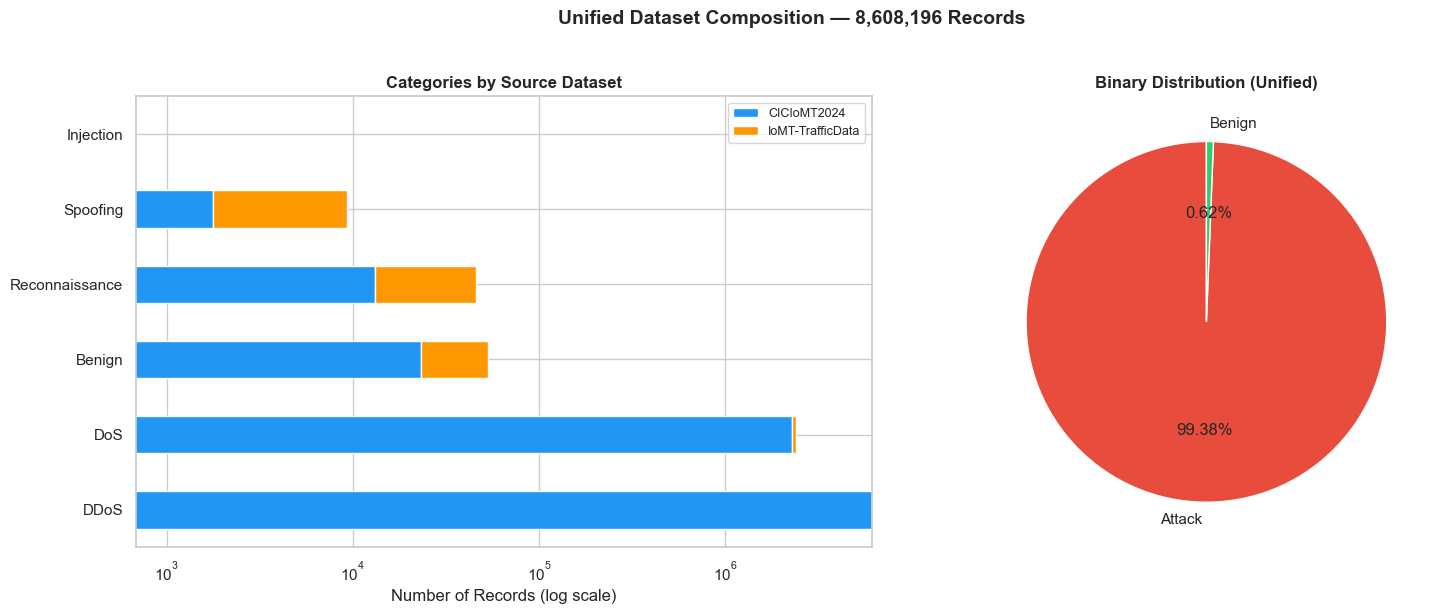

In [14]:
# Visualize unified composition
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: categories by source
cat_by_source = unified.groupby(['label_category', 'source_dataset']).size().unstack(fill_value=0)
cat_order = ['DDoS', 'DoS', 'Benign', 'Reconnaissance', 'Spoofing', 'Injection']
cat_by_source = cat_by_source.reindex([c for c in cat_order if c in cat_by_source.index])
cat_by_source.plot(kind='barh', stacked=True, ax=axes[0],
                    color=['#2196F3', '#FF9800'])
axes[0].set_title('Categories by Source Dataset', fontweight='bold')
axes[0].set_xlabel('Number of Records (log scale)')
axes[0].set_xscale('log')
axes[0].set_ylabel('')
axes[0].legend(fontsize=9)

# Right: binary distribution
binary_counts = unified['label_binary'].value_counts()
wedges, texts, autotexts = axes[1].pie(
    binary_counts.values, labels=binary_counts.index,
    autopct='%1.2f%%', startangle=90,
    colors=['#e74c3c', '#2ecc71'])
axes[1].set_title('Binary Distribution (Unified)', fontweight='bold')

plt.suptitle(f'Unified Dataset Composition — {len(unified):,} Records',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Stage 5: Data Quality Assurance

Apply the 6-step QA pipeline from Section 3.6:
1. Missing value treatment (drop >50% NaN features, impute rest with 0)
2. Infinity value handling (replace ±inf with finite max/min)
3. Zero-variance feature removal
4. Near-zero-variance detection (flag only, do not remove)
5. Duplicate removal (feature-based deduplication)
6. Type consistency (cast to float32)

In [15]:
print('='*70)
print('STAGE 5: Data Quality Assurance')
print('='*70)

feature_cols = get_feature_columns(unified)
feature_cols = [c for c in feature_cols
                if c not in ['label_binary', 'label_category', 'label_fine']]
print(f'Starting QA with {len(feature_cols)} features and {len(unified):,} rows')

# Pre-QA diagnostics
print(f'\n--- Pre-QA NaN Analysis ---')
nan_rates = unified[feature_cols].isna().mean()
high_nan = nan_rates[nan_rates > 0.5]
print(f'Features with >50% NaN: {len(high_nan)}')
for col, rate in high_nan.items():
    print(f'  {col}: {rate:.4f} ({rate*100:.2f}%)')

total_nan = unified[feature_cols].isna().sum().sum()
print(f'\nTotal NaN values: {total_nan:,}')
inf_count = np.isinf(unified[feature_cols].select_dtypes(include=[np.number])).sum().sum()
print(f'Total infinity values: {inf_count:,}')

STAGE 5: Data Quality Assurance
Starting QA with 73 features and 8,608,196 rows

--- Pre-QA NaN Analysis ---


Features with >50% NaN: 8
  fin_flag_number: 0.9828 (98.28%)
  syn_flag_number: 0.9828 (98.28%)
  rst_flag_number: 0.9828 (98.28%)
  psh_flag_number: 0.9828 (98.28%)
  ack_flag_number: 0.9828 (98.28%)
  ece_flag_number: 0.9828 (98.28%)
  cwr_flag_number: 0.9828 (98.28%)
  tcp_flags_ece: 0.9828 (98.28%)



Total NaN values: 67,678,737
Total infinity values: 0


In [16]:
# Run the full QA pipeline
unified_qa, feature_cols_qa, near_zero_feats = run_full_qa(unified, feature_cols)


Data Quality Assurance Pipeline

--- Step 1: Missing Value Treatment ---


  [QA] Dropping 8 features with NaN rate > 0.5:
  [QA]     fin_flag_number: 98.28%
  [QA]     syn_flag_number: 98.28%
  [QA]     rst_flag_number: 98.28%
  [QA]     psh_flag_number: 98.28%
  [QA]     ack_flag_number: 98.28%
  [QA]     ece_flag_number: 98.28%
  [QA]     cwr_flag_number: 98.28%
  [QA]     tcp_flags_ece: 98.28%


  [QA] Imputing 1 remaining NaN values with 0



--- Step 2: Infinity Value Handling ---


  [QA] No infinity values found

--- Step 3: Zero-Variance Feature Removal ---


  [QA] Removing 7 zero-variance features: ['DHCP', 'ARP', 'IPV4', 'LLC', 'Drate', 'Fwd_Data_Pkts_Tot', 'Bwd_Data_Pkts_Tot']



--- Step 4: Near-Zero-Variance Detection ---


  [QA] Near-zero-variance features (4 flagged): ['IGMP', 'Fwd_IAT', 'Bwd_IAT', 'Flow_IAT']

--- Step 5: Duplicate Removal ---


  [QA] Removed 596,662 duplicate rows (6.93%)

--- Step 6: Type Consistency ---


  [QA] Converted 58 columns to float32

--- QA Complete ---
  Final shape: 8,011,534 rows × 58 features


In [17]:
# Post-QA summary
print(f'\n--- Post-QA Summary ---')
print(f'Rows:     {len(unified):,} → {len(unified_qa):,} (removed {len(unified)-len(unified_qa):,}, {100*(len(unified)-len(unified_qa))/len(unified):.2f}%)')
print(f'Features: {len(feature_cols)} → {len(feature_cols_qa)} (removed {len(feature_cols)-len(feature_cols_qa)})')
print(f'  - High NaN features dropped: {len(feature_cols) - 65}')  
print(f'  - Zero-variance features dropped: {65 - len(feature_cols_qa)}')
print(f'  - Near-zero-variance (flagged, not removed): {len(near_zero_feats)} → {near_zero_feats}')
print(f'\nRemaining NaN: {unified_qa[feature_cols_qa].isna().sum().sum()}')
print(f'Remaining Inf: {np.isinf(unified_qa[feature_cols_qa].select_dtypes(include=[np.number])).sum().sum()}')
print(f'Data type: {unified_qa[feature_cols_qa[0]].dtype}')


--- Post-QA Summary ---
Rows:     8,608,196 → 8,011,534 (removed 596,662, 6.93%)
Features: 73 → 58 (removed 15)
  - High NaN features dropped: 8
  - Zero-variance features dropped: 7
  - Near-zero-variance (flagged, not removed): 4 → ['IGMP', 'Fwd_IAT', 'Bwd_IAT', 'Flow_IAT']



Remaining NaN: 0
Remaining Inf: 0
Data type: float32


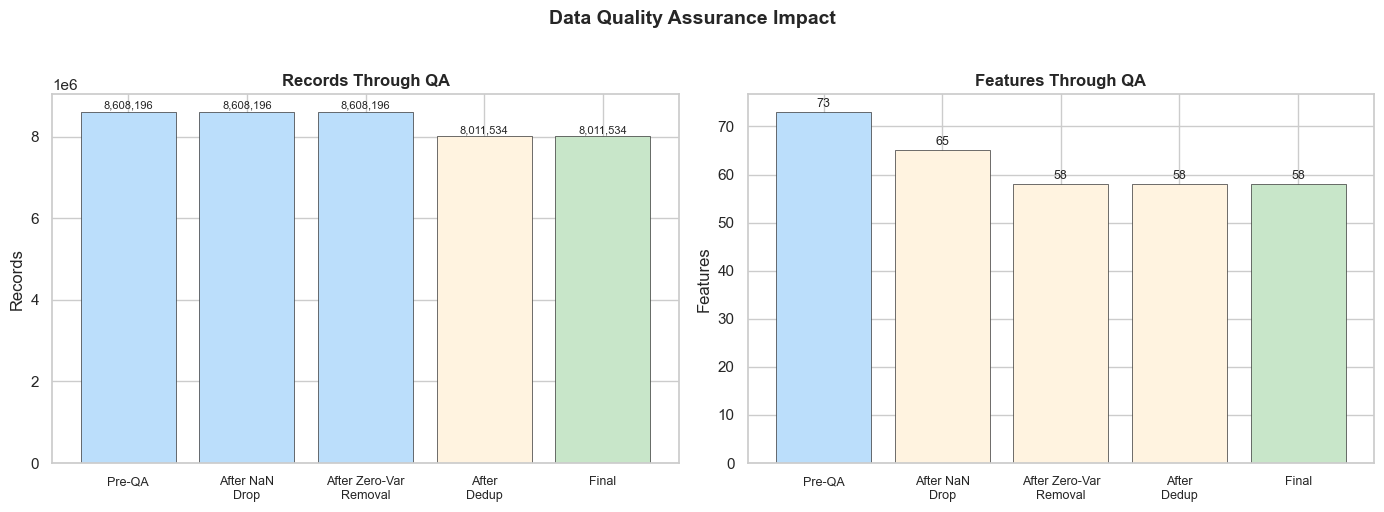

In [18]:
# Visualize QA impact
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

stages = ['Pre-QA', 'After NaN\nDrop', 'After Zero-Var\nRemoval', 'After\nDedup', 'Final']
rows = [len(unified), len(unified), len(unified), len(unified_qa), len(unified_qa)]
features = [73, 65, 58, 58, 58]

colors_r = ['#BBDEFB', '#BBDEFB', '#BBDEFB', '#FFF3E0', '#C8E6C9']
bars1 = ax1.bar(range(len(stages)), rows, color=colors_r, edgecolor='#333', linewidth=0.5)
ax1.set_xticks(range(len(stages)))
ax1.set_xticklabels(stages, fontsize=9)
ax1.set_ylabel('Records')
ax1.set_title('Records Through QA', fontweight='bold')
for bar, val in zip(bars1, rows):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 30000, f'{val:,}',
             ha='center', va='bottom', fontsize=8)

colors_f = ['#BBDEFB', '#FFF3E0', '#FFF3E0', '#FFF3E0', '#C8E6C9']
bars2 = ax2.bar(range(len(stages)), features, color=colors_f, edgecolor='#333', linewidth=0.5)
ax2.set_xticks(range(len(stages)))
ax2.set_xticklabels(stages, fontsize=9)
ax2.set_ylabel('Features')
ax2.set_title('Features Through QA', fontweight='bold')
for bar, val in zip(bars2, features):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.5, str(val),
             ha='center', va='bottom', fontsize=9)

plt.suptitle('Data Quality Assurance Impact', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Stage 6: Stratified Splitting

Split the unified dataset into train/val/test (70/15/15%) using stratification
on the composite key `label_category × source_dataset` to preserve both
category and source proportions across all partitions.

In [19]:
print('='*70)
print('STAGE 6: Stratified Splitting')
print('='*70)

splits = stratified_split(unified_qa, feature_cols_qa)
print_split_distribution(splits)

STAGE 6: Stratified Splitting



--- Stratified Split ---
  train:  5,608,073 rows (70.0%)
  val  :  1,201,730 rows (15.0%)
  test :  1,201,731 rows (15.0%)

  [TRAIN] label_category distribution:
    DDoS                 3,933,368  ( 70.1%)
    DoS                  1,598,044  ( 28.5%)
    Benign                 37,419  (  0.7%)
    Reconnaissance         32,218  (  0.6%)
    Spoofing                6,542  (  0.1%)
    Injection                 482  (  0.0%)
  [TRAIN] source_dataset distribution:


    CICIoMT2024          5,479,105  ( 97.7%)
    IoMT-TrafficData      128,968  (  2.3%)

  [VAL] label_category distribution:
    DDoS                  842,865  ( 70.1%)
    DoS                   342,437  ( 28.5%)
    Benign                  8,018  (  0.7%)
    Reconnaissance          6,904  (  0.6%)
    Spoofing                1,402  (  0.1%)
    Injection                 104  (  0.0%)
  [VAL] source_dataset distribution:
    CICIoMT2024          1,174,094  ( 97.7%)
    IoMT-TrafficData       27,636  (  2.3%)

  [TEST] label_category distribution:
    DDoS                  842,865  ( 70.1%)
    DoS                   342,439  ( 28.5%)
    Benign                  8,019  (  0.7%)
    Reconnaissance          6,904  (  0.6%)
    Spoofing                1,401  (  0.1%)
    Injection                 103  (  0.0%)
  [TEST] source_dataset distribution:
    CICIoMT2024          1,174,094  ( 97.7%)
    IoMT-TrafficData       27,637  (  2.3%)


In [20]:
# Verify stratification quality
print('\n--- Stratification Verification ---')
cat_order = ['DDoS', 'DoS', 'Benign', 'Reconnaissance', 'Spoofing', 'Injection']
print(f'{"Category":<20s} {"Train %":>10s} {"Val %":>10s} {"Test %":>10s} {"Δ max":>10s}')
print('-'*65)
for cat in cat_order:
    pcts = []
    for name in ['train', 'val', 'test']:
        cnt = (splits[name]['label_category'] == cat).sum()
        pcts.append(100 * cnt / len(splits[name]))
    delta = max(pcts) - min(pcts)
    print(f'{cat:<20s} {pcts[0]:>9.4f}% {pcts[1]:>9.4f}% {pcts[2]:>9.4f}% {delta:>9.4f}%')

print(f'\n{"Source":<20s} {"Train %":>10s} {"Val %":>10s} {"Test %":>10s} {"Δ max":>10s}')
print('-'*65)
for src in ['CICIoMT2024', 'IoMT-TrafficData']:
    pcts = []
    for name in ['train', 'val', 'test']:
        cnt = (splits[name]['source_dataset'] == src).sum()
        pcts.append(100 * cnt / len(splits[name]))
    delta = max(pcts) - min(pcts)
    print(f'{src:<20s} {pcts[0]:>9.4f}% {pcts[1]:>9.4f}% {pcts[2]:>9.4f}% {delta:>9.4f}%')


--- Stratification Verification ---
Category                Train %      Val %     Test %      Δ max
-----------------------------------------------------------------


DDoS                   70.1376%   70.1376%   70.1376%    0.0001%


DoS                    28.4954%   28.4953%   28.4955%    0.0001%


Benign                  0.6672%    0.6672%    0.6673%    0.0001%


Reconnaissance          0.5745%    0.5745%    0.5745%    0.0000%


Spoofing                0.1167%    0.1167%    0.1166%    0.0001%


Injection               0.0086%    0.0087%    0.0086%    0.0001%

Source                  Train %      Val %     Test %      Δ max
-----------------------------------------------------------------


CICIoMT2024            97.7003%   97.7003%   97.7002%    0.0001%


IoMT-TrafficData        2.2997%    2.2997%    2.2998%    0.0001%


---
## Stage 7: Feature Scaling

Apply z-score standardization fitted on the **training set only** to prevent data leakage.
All 58 features are transformed to approximately zero mean and unit variance.

In [21]:
print('='*70)
print('STAGE 7: Feature Scaling')
print('='*70)

scaled_splits, scaler = apply_scaling(splits, feature_cols_qa)

print(f'\n--- Post-Scaling Verification ---')
for name in ['train', 'val', 'test']:
    means = scaled_splits[name][feature_cols_qa].mean()
    stds = scaled_splits[name][feature_cols_qa].std()
    print(f'  {name:5s}: mean={means.mean():.8f}, std={stds.mean():.8f}')

STAGE 7: Feature Scaling



--- Scaling (StandardScaler fitted on train) ---


  Train mean ≈ 0.000000


  Train std  ≈ 1.000000

--- Post-Scaling Verification ---


  train: mean=0.00000001, std=1.00000000
  val  : mean=-0.00025954, std=0.97033590


  test : mean=0.00007509, std=0.95614547


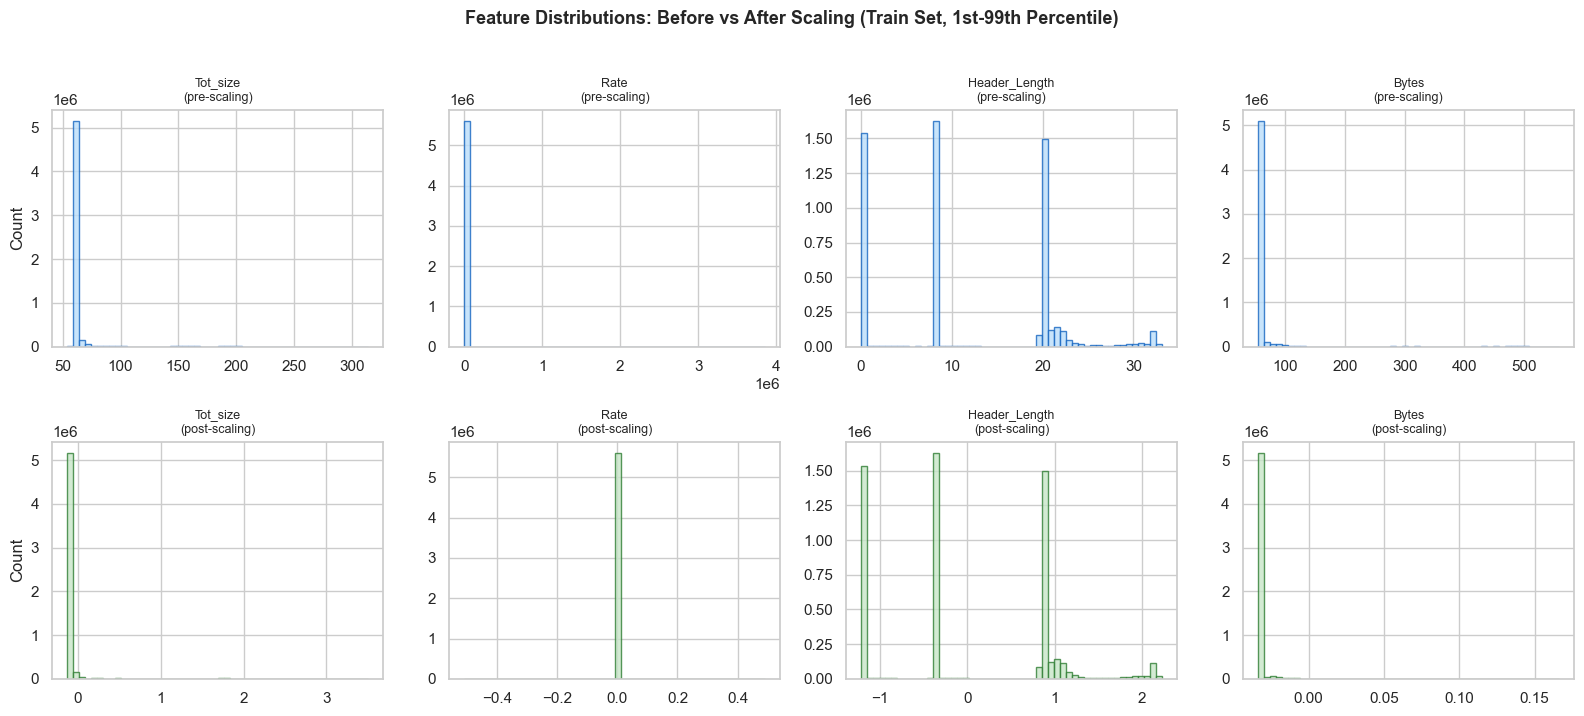

In [22]:
# Visualize feature distributions before and after scaling (sample features)
sample_feats = ['Tot_size', 'Rate', 'Header_Length', 'Bytes']
fig, axes = plt.subplots(2, len(sample_feats), figsize=(16, 7))

for j, feat in enumerate(sample_feats):
    # Before scaling
    vals_before = splits['train'][feat].replace([np.inf, -np.inf], np.nan).dropna()
    p99 = vals_before.quantile(0.99)
    if p99 > 0:
        vals_before = vals_before[vals_before <= p99]
    axes[0, j].hist(vals_before, bins=50, color='#BBDEFB', edgecolor='#1565C0', alpha=0.8)
    axes[0, j].set_title(f'{feat}\n(pre-scaling)', fontsize=9)
    if j == 0: axes[0, j].set_ylabel('Count')

    # After scaling
    vals_after = scaled_splits['train'][feat].replace([np.inf, -np.inf], np.nan).dropna()
    p99a = vals_after.quantile(0.99)
    p01a = vals_after.quantile(0.01)
    vals_after = vals_after[(vals_after >= p01a) & (vals_after <= p99a)]
    axes[1, j].hist(vals_after, bins=50, color='#C8E6C9', edgecolor='#2E7D32', alpha=0.8)
    axes[1, j].set_title(f'{feat}\n(post-scaling)', fontsize=9)
    if j == 0: axes[1, j].set_ylabel('Count')

plt.suptitle('Feature Distributions: Before vs After Scaling (Train Set, 1st-99th Percentile)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## Stage 8: Export & Final Verification

Save the unified dataset splits (CSV), the fitted scaler, and pipeline metadata.

In [23]:
print('='*70)
print('STAGE 8: Export')
print('='*70)

save_splits(scaled_splits, scaler, feature_cols_qa, near_zero_feats)
print('\nPhase 1 unification complete.')

STAGE 8: Export


  Saved train: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified/train.csv (5,608,073 rows)


  Saved val: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified/val.csv (1,201,730 rows)


  Saved test: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified/test.csv (1,201,731 rows)
  Saved scaler: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified/scaler.joblib
  Saved metadata: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified/metadata.joblib

  All Phase 1 artifacts saved to: /Users/pantelos/Documents/diploma_thesis/data/processed/phase1_iomt_unified

Phase 1 unification complete.


In [24]:
# Final comprehensive summary
print('\n' + '='*70)
print('FINAL UNIFIED DATASET SUMMARY')
print('='*70)
total_rows = sum(len(s) for s in scaled_splits.values())
print(f'\nTotal records:       {total_rows:,}')
print(f'Number of features:  {len(feature_cols_qa)}')
print(f'Feature dtype:       float32')
print(f'Scaling:             StandardScaler (z-score, fitted on train)')
print(f'\nSplit sizes:')
for name, split_df in scaled_splits.items():
    print(f'  {name:5s}: {len(split_df):>10,} ({100*len(split_df)/total_rows:.1f}%)')

print(f'\nLabel levels:')
print(f'  Binary:       {unified_qa["label_binary"].nunique()} classes')
print(f'  Category:     {unified_qa["label_category"].nunique()} classes')
print(f'  Fine-grained: {unified_qa["label_fine"].nunique()} classes')

print(f'\nCategories ({unified_qa["label_category"].nunique()}):')
for cat in sorted(unified_qa['label_category'].unique()):
    cnt = (unified_qa['label_category'] == cat).sum()
    print(f'  {cat:20s} {cnt:>10,} ({100*cnt/len(unified_qa):.2f}%)')

print(f'\nSource datasets:')
for src in sorted(unified_qa['source_dataset'].unique()):
    cnt = (unified_qa['source_dataset'] == src).sum()
    print(f'  {src:20s} {cnt:>10,} ({100*cnt/len(unified_qa):.2f}%)')

print(f'\nFine-grained attack types ({unified_qa["label_fine"].nunique()}):')
for lbl, cnt in unified_qa['label_fine'].value_counts().items():
    src = unified_qa[unified_qa['label_fine']==lbl]['source_dataset'].iloc[0]
    print(f'  {lbl:35s} {cnt:>10,} ({100*cnt/len(unified_qa):.4f}%)  [{src}]')


FINAL UNIFIED DATASET SUMMARY

Total records:       8,011,534
Number of features:  58
Feature dtype:       float32
Scaling:             StandardScaler (z-score, fitted on train)

Split sizes:
  train:  5,608,073 (70.0%)
  val  :  1,201,730 (15.0%)
  test :  1,201,731 (15.0%)

Label levels:
  Binary:       2 classes


  Category:     6 classes
  Fine-grained: 26 classes



Categories (6):


  Benign                   53,456 (0.67%)
  DDoS                  5,619,098 (70.14%)


  DoS                   2,282,920 (28.50%)
  Injection                   689 (0.01%)


  Reconnaissance           46,026 (0.57%)
  Spoofing                  9,345 (0.12%)

Source datasets:


... (15 outputs left out)

  RUDY                                     7,809 (0.0975%)  [IoMT-TrafficData]
  SlowLoris                                3,778 (0.0472%)  [IoMT-TrafficData]


  Recon-OS_Scan                            2,068 (0.0258%)  [CICIoMT2024]
  SlowRead                                 1,399 (0.0175%)  [IoMT-TrafficData]


  MQTT-Malformed_Data                        689 (0.0086%)  [CICIoMT2024]
  Recon-VulScan                              322 (0.0040%)  [CICIoMT2024]


  Recon-Ping_Sweep                            94 (0.0012%)  [CICIoMT2024]


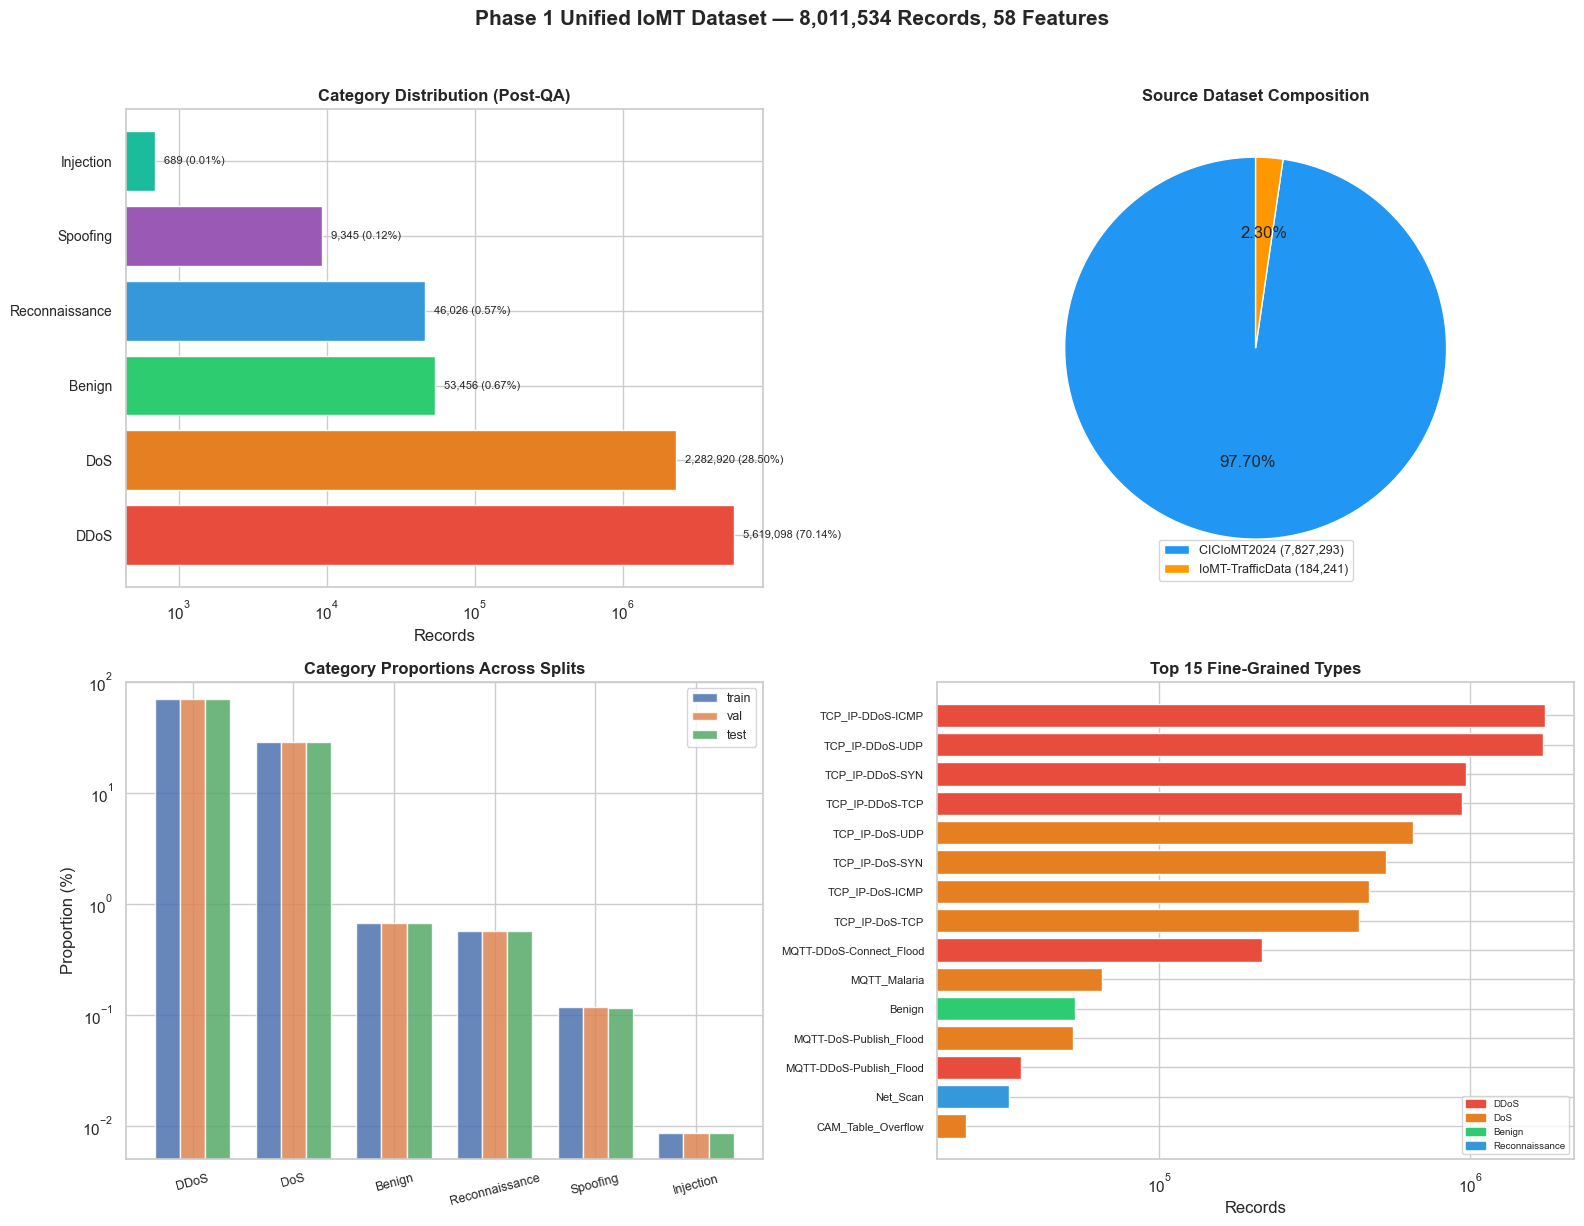


✓ Phase 1 Pipeline Complete


In [25]:
# Final visualization: unified dataset overview
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

cat_colors_map = {
    'DDoS': '#e74c3c', 'DoS': '#e67e22', 'Benign': '#2ecc71',
    'Reconnaissance': '#3498db', 'Spoofing': '#9b59b6', 'Injection': '#1abc9c',
}
src_colors = {'CICIoMT2024': '#2196F3', 'IoMT-TrafficData': '#FF9800'}

# 1. Category distribution
ax = axes[0, 0]
cat_counts = unified_qa['label_category'].value_counts()
cat_counts = cat_counts.reindex([c for c in cat_order if c in cat_counts.index])
colors = [cat_colors_map.get(c, '#95a5a6') for c in cat_counts.index]
bars = ax.barh(range(len(cat_counts)), cat_counts.values, color=colors, edgecolor='white')
ax.set_yticks(range(len(cat_counts)))
ax.set_yticklabels(cat_counts.index, fontsize=10)
ax.set_xlabel('Records')
ax.set_xscale('log')
ax.set_title('Category Distribution (Post-QA)', fontweight='bold')
for bar, val in zip(bars, cat_counts.values):
    ax.text(val * 1.15, bar.get_y() + bar.get_height()/2,
            f'{val:,} ({100*val/len(unified_qa):.2f}%)', va='center', fontsize=8)

# 2. Source distribution
ax = axes[0, 1]
src_counts = unified_qa['source_dataset'].value_counts()
wedges, texts, autotexts = ax.pie(
    src_counts.values, labels=None,
    autopct='%1.2f%%', startangle=90,
    colors=[src_colors.get(s, '#95a5a6') for s in src_counts.index])
ax.legend(wedges, [f'{s} ({c:,})' for s, c in src_counts.items()],
          loc='lower center', fontsize=9)
ax.set_title('Source Dataset Composition', fontweight='bold')

# 3. Split category proportions
ax = axes[1, 0]
x = np.arange(len(cat_order))
width = 0.25
for i, name in enumerate(['train', 'val', 'test']):
    proportions = [(scaled_splits[name]['label_category'] == c).sum() / len(scaled_splits[name]) * 100
                   for c in cat_order]
    ax.bar(x + i * width, proportions, width, label=name, alpha=0.85)
ax.set_xticks(x + width)
ax.set_xticklabels(cat_order, fontsize=9, rotation=15)
ax.set_ylabel('Proportion (%)')
ax.set_yscale('log')
ax.set_ylim(0.005, 100)
ax.set_title('Category Proportions Across Splits', fontweight='bold')
ax.legend(fontsize=9)

# 4. Fine-grained top 15
ax = axes[1, 1]
fine_counts = unified_qa['label_fine'].value_counts().head(15)
fine_cats = [unified_qa[unified_qa['label_fine'] == l]['label_category'].iloc[0]
             for l in fine_counts.index]
fcolors = [cat_colors_map.get(c, '#95a5a6') for c in fine_cats]
bars = ax.barh(range(len(fine_counts)), fine_counts.values[::-1],
               color=fcolors[::-1], edgecolor='white')
ax.set_yticks(range(len(fine_counts)))
ax.set_yticklabels(fine_counts.index[::-1], fontsize=8)
ax.set_xlabel('Records')
ax.set_xscale('log')
ax.set_title('Top 15 Fine-Grained Types', fontweight='bold')
handles = [mpatches.Patch(color=cat_colors_map[c], label=c) for c in cat_order if c in set(fine_cats)]
ax.legend(handles=handles, fontsize=7, loc='lower right')

plt.suptitle(f'Phase 1 Unified IoMT Dataset — {total_rows:,} Records, {len(feature_cols_qa)} Features',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

print('\n✓ Phase 1 Pipeline Complete')

---
## MQTT-Category Variant (New Dataset)

This section documents the new Phase 1 dataset variant where **all MQTT-related attacks are mapped to a dedicated `MQTT` category**.

- Pipeline run: `python src/pipeline/run_phase1.py --category-scheme mqtt`
- Output directory: `data/processed/phase1_iomt_unified_mqtt_category/`
- Scaling strategy: **StandardScaler fit on train only**, then `transform` on train/val/test (same policy as the original pipeline).


MQTT-CATEGORY DATASET SUMMARY
Rows: 8,011,534
Features: 58
Category scheme: mqtt
Split sizes: {'train': 5608073, 'val': 1201730, 'test': 1201731}

Category distribution:


  DDoS                  5,368,292 (67.01%)
  DoS                   2,148,477 (26.82%)
  MQTT                    385,938 ( 4.82%)
  Benign                   53,456 ( 0.67%)
  Reconnaissance           46,026 ( 0.57%)
  Spoofing                  9,345 ( 0.12%)

Source distribution:


  CICIoMT2024           7,827,293 (97.70%)
  IoMT-TrafficData        184,241 ( 2.30%)


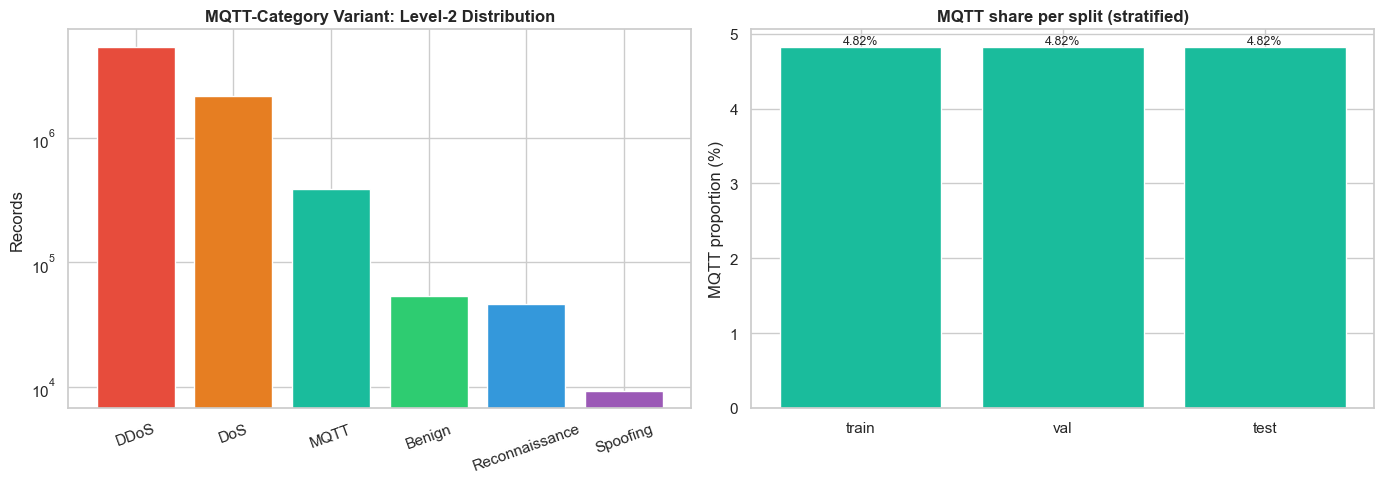

In [26]:
import joblib
from pathlib import Path

mqtt_dir = Path('../data/processed/phase1_iomt_unified_mqtt_category')
train_mqtt = pd.read_csv(mqtt_dir / 'train.csv', usecols=['label_category', 'label_binary', 'source_dataset'])
val_mqtt = pd.read_csv(mqtt_dir / 'val.csv', usecols=['label_category', 'label_binary', 'source_dataset'])
test_mqtt = pd.read_csv(mqtt_dir / 'test.csv', usecols=['label_category', 'label_binary', 'source_dataset'])
meta_mqtt = joblib.load(mqtt_dir / 'metadata.joblib')

mqtt_all = pd.concat([train_mqtt, val_mqtt, test_mqtt], ignore_index=True)

print('='*70)
print('MQTT-CATEGORY DATASET SUMMARY')
print('='*70)
print(f"Rows: {len(mqtt_all):,}")
print(f"Features: {len(meta_mqtt['feature_cols'])}")
print(f"Category scheme: {meta_mqtt.get('category_scheme')}")
print(f"Split sizes: {meta_mqtt['split_sizes']}")

print('\nCategory distribution:')
for cat, cnt in mqtt_all['label_category'].value_counts().items():
    print(f"  {cat:20s} {cnt:>10,} ({100*cnt/len(mqtt_all):5.2f}%)")

print('\nSource distribution:')
for src, cnt in mqtt_all['source_dataset'].value_counts().items():
    print(f"  {src:20s} {cnt:>10,} ({100*cnt/len(mqtt_all):5.2f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cat_counts = mqtt_all['label_category'].value_counts()
colors = ['#e74c3c','#e67e22','#1abc9c','#2ecc71','#3498db','#9b59b6']
axes[0].bar(cat_counts.index, cat_counts.values, color=colors[:len(cat_counts)], edgecolor='white')
axes[0].set_title('MQTT-Category Variant: Level-2 Distribution', fontweight='bold')
axes[0].set_ylabel('Records')
axes[0].tick_params(axis='x', rotation=20)
axes[0].set_yscale('log')

split_names = ['train', 'val', 'test']
split_dfs = [train_mqtt, val_mqtt, test_mqtt]
for i, split_df in enumerate(split_dfs):
    pct = (split_df['label_category'] == 'MQTT').mean() * 100
    axes[1].bar(split_names[i], pct, color='#1abc9c', edgecolor='white')
    axes[1].text(i, pct + 0.05, f'{pct:.2f}%', ha='center', fontsize=9)
axes[1].set_title('MQTT share per split (stratified)', fontweight='bold')
axes[1].set_ylabel('MQTT proportion (%)')

plt.tight_layout()
plt.show()